In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, measure, morphology
import scipy.ndimage as ndi

print("ready")

Matplotlib is building the font cache; this may take a moment.


ready


In [2]:
img = data.human_mitosis()  # grayscale cell image, stand-in for stained tissue
plt.figure(figsize=(6,6))
plt.imshow(img, cmap="gray")
plt.title("Placeholder image (not real cerebellar tissue)")
plt.axis("off")
plt.show()

ModuleNotFoundError: The requested file is part of the scikit-image distribution, but requires the installation of an optional dependency, pooch. To install pooch, use your preferred python package manager. Follow installation instruction found at https://scikit-image.org/docs/stable/user_guide/install.html

In [3]:
%pip install pooch

Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, measure, morphology
import scipy.ndimage as ndi

print("ready")

ready


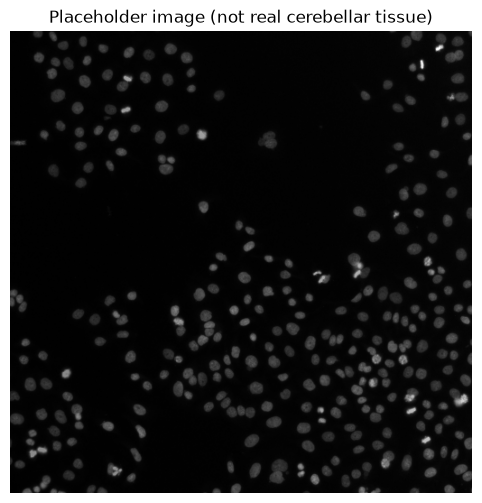

In [2]:
img = data.human_mitosis()
plt.figure(figsize=(6,6))
plt.imshow(img, cmap="gray")
plt.title("Placeholder image (not real cerebellar tissue)")
plt.axis("off")
plt.show()

In [5]:
import os
print(os.getcwd())
print(os.listdir())


/Users/georgerivera/cerebellar-thickness
['Untitled.ipynb', '01_explore.ipynb', 'README.md', '.gitignore', '.virtual_documents', '.ipynb_checkpoints', '.git', 'notebooks']


In [4]:
from skimage import io

cerebellum = io.imread("data/100149965_1983.jpg")
print(cerebellum.shape, cerebellum.dtype)

plt.figure(figsize=(8,8))
plt.imshow(cerebellum)
plt.title("Allen Human Brain Atlas — downloaded section")
plt.axis("off")
plt.show()

(543, 551, 3) uint8


NameError: name 'plt' is not defined

In [3]:
import os
print(os.getcwd())
print(os.listdir())

/Users/georgerivera/cerebellar-thickness/notebooks
['.gitkeep', '01_explore.ipynb', '.ipynb_checkpoints']


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, measure, morphology, io
import scipy.ndimage as ndi

print("ready")


ready


(543, 551, 3) uint8


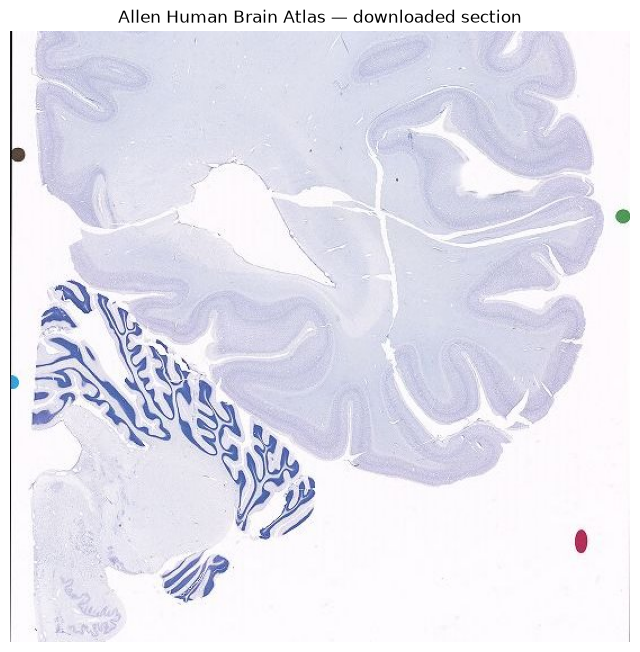

In [6]:
cerebellum = io.imread("data/100149965_1983.jpg")
print(cerebellum.shape, cerebellum.dtype)

plt.figure(figsize=(8,8))
plt.imshow(cerebellum)
plt.title("Allen Human Brain Atlas — downloaded section")
plt.axis("off")
plt.show()

(543, 551) float64 0.0008333333333333333 1.0


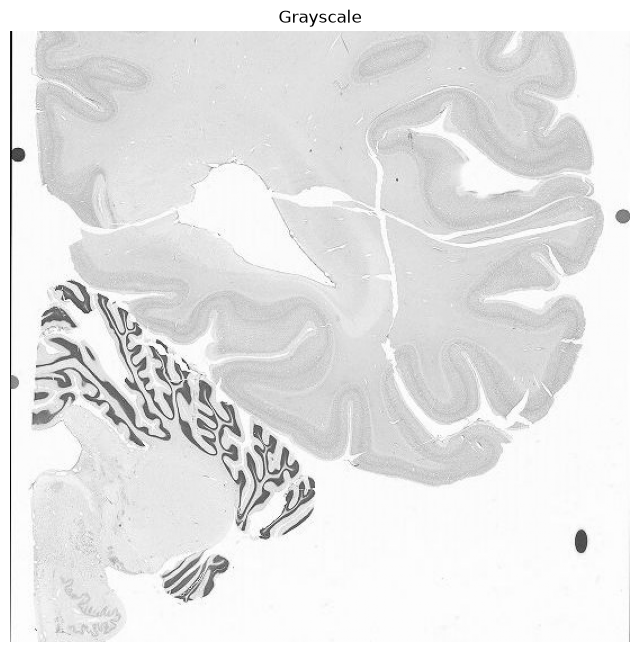

In [7]:
from skimage.color import rgb2gray

gray = rgb2gray(cerebellum)
print(gray.shape, gray.dtype, gray.min(), gray.max())

plt.figure(figsize=(8,8))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")
plt.show()

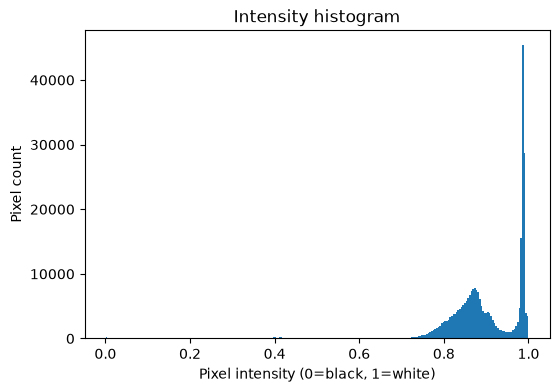

In [8]:
plt.figure(figsize=(6,4))
plt.hist(gray.ravel(), bins=256)
plt.title("Intensity histogram")
plt.xlabel("Pixel intensity (0=black, 1=white)")
plt.ylabel("Pixel count")
plt.show()

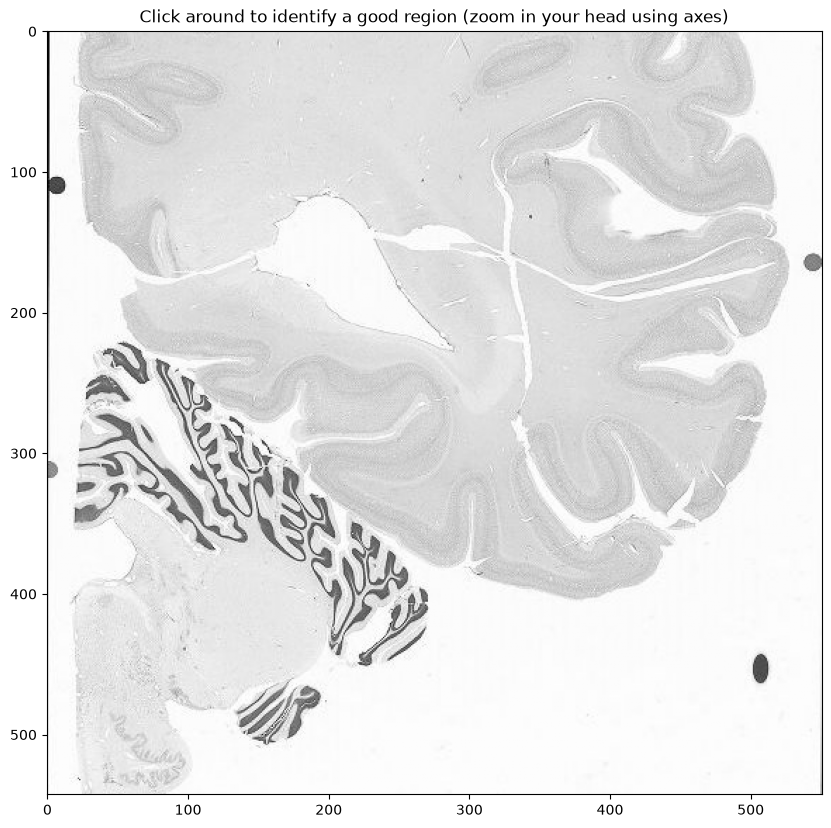

In [9]:
plt.figure(figsize=(10,10))
plt.imshow(gray, cmap="gray")
plt.title("Click around to identify a good region (zoom in your head using axes)")
plt.show()

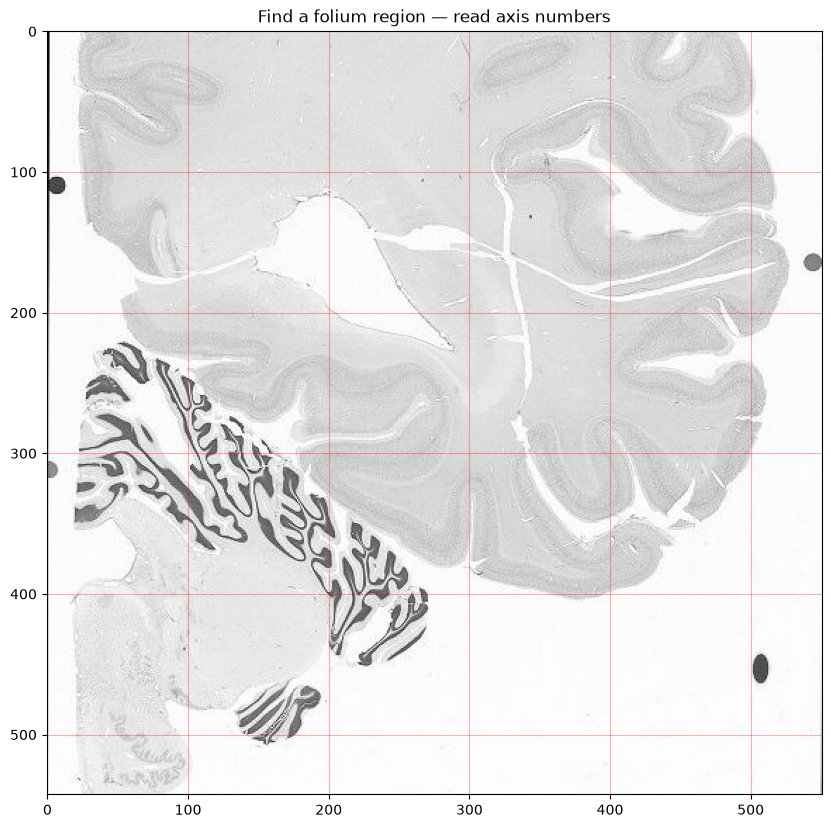

In [10]:
plt.figure(figsize=(10,10))
plt.imshow(gray, cmap="gray")
plt.title("Find a folium region — read axis numbers")
plt.grid(color='red', alpha=0.3)
plt.show()

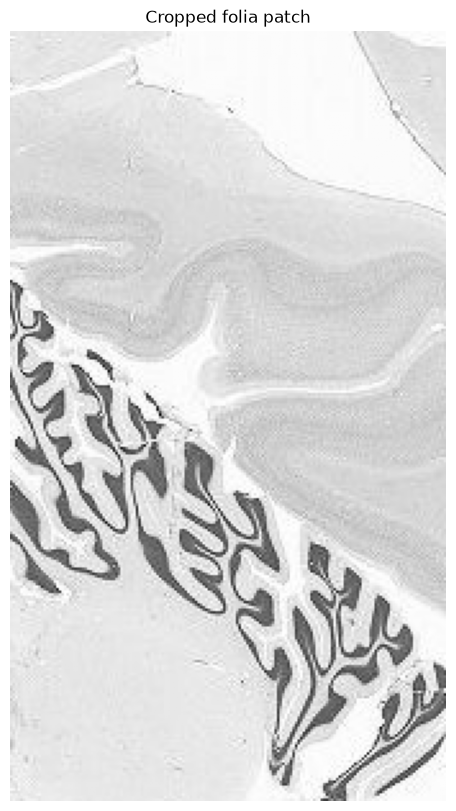

In [12]:
patch = gray[150:450, 100:270]

plt.figure(figsize=(8,10))
plt.imshow(patch, cmap="gray")
plt.title("Cropped folia patch")
plt.axis("off")
plt.show()

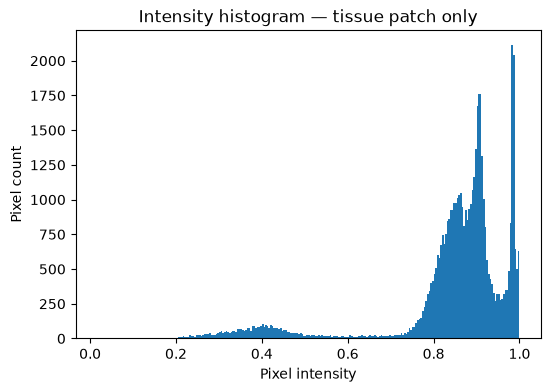

In [13]:
plt.figure(figsize=(6,4))
plt.hist(patch.ravel(), bins=256)
plt.title("Intensity histogram — tissue patch only")
plt.xlabel("Pixel intensity")
plt.ylabel("Pixel count")
plt.show()

Thresholds: [0.61350376 0.88270512]


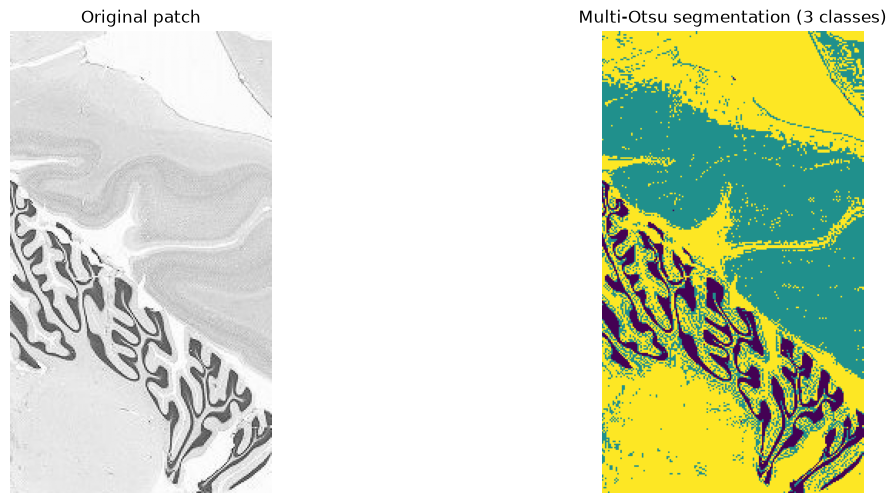

In [14]:
from skimage.filters import threshold_multiotsu

# Try 3 classes first: background, molecular layer, granular layer
thresholds = threshold_multiotsu(patch, classes=3)
print("Thresholds:", thresholds)

regions = np.digitize(patch, bins=thresholds)

plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
plt.imshow(patch, cmap="gray")
plt.title("Original patch")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(regions, cmap="viridis")
plt.title("Multi-Otsu segmentation (3 classes)")
plt.axis("off")

plt.show()